In [1]:
# ==========================================
# 1. โหลดไลบรารีและกำหนดค่าการแสดงผล
# ==========================================

import os
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ตั้งค่าธีมกราฟและรูปแบบการแสดงผลตัวเลขทศนิยม 2 ตำแหน่งในตาราง pandas
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# ดาวน์โหลดชุดข้อมูล Lending Club เวอร์ชันล่าสุดลงเครื่องและเก็บตำแหน่งโฟลเดอร์ไว้ในตัวแปร path
path = kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv")
print("Path to dataset files:", path)

# ค้นหาไฟล์ CSV ในโฟลเดอร์และกำหนดรายชื่อคอลัมน์สำคัญที่ต้องการดึงมาวิเคราะห์ (เพื่อประหยัด RAM)
csv_files = [f for f in os.listdir(path) if f.endswith(".csv")]
key_columns = [
    "loan_amnt", "funded_amnt", "term", "int_rate", "installment",
    "grade", "sub_grade", "emp_length", "home_ownership", "annual_inc",
    "verification_status", "issue_d", "loan_status", "purpose", "addr_state",
    "dti", "earliest_cr_line", "open_acc", "pub_rec", "revol_bal",
    "revol_util", "total_acc", "total_pymnt", "mort_acc", "pub_rec_bankruptcies"
]

# อ่านไฟล์ loan.csv เฉพาะคอลัมน์ที่กำหนดเข้าสู่ DataFrame
loans_raw = pd.read_csv(f"{path}/{csv_files[0]}", usecols=lambda c: c in key_columns, low_memory=False)

# ตรวจสอบขนาดของ DataFrame (จำนวนแถว, จำนวนคอลัมน์)
print("\nData loaded successfully:")
print(f"- Loans Raw ({csv_files[0]}): {loans_raw.shape}")

Path to dataset files: C:\Users\User\.cache\kagglehub\datasets\adarshsng\lending-club-loan-data-csv\versions\1

Data loaded successfully:
- Loans Raw (loan.csv): (2260668, 25)


In [2]:
# ==========================================
# 2. ทำความสะอาดข้อมูล (Data Cleaning)
# ==========================================

# ตรวจสอบคอลัมน์ id (ในชุดข้อมูลนี้คอลัมน์ id เป็นค่าว่างทั้งไฟล์ จึงข้ามการโหลดและสร้าง loan_id ใหม่ภายหลัง)
print("Non-null id values:", loans_raw["id"].notna().sum() if "id" in loans_raw.columns else "id column not loaded (all-NaN in this dataset)")

# 1. กรองเฉพาะสินเชื่อที่ทราบผลลัพธ์สุดท้ายแล้ว ('Fully Paid' และ 'Charged Off') โดยตัด 'Current' ที่ยังผ่อนไม่จบออก
completed_loans = loans_raw[loans_raw["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()

# 2. แปลงชนิดข้อมูล (Data Type Parsing)
# ตัดคำว่า ' months' ออกจากคอลัมน์ term และแปลงเป็นตัวเลข (36, 60)
completed_loans["term_months"] = completed_loans["term"].str.extract(r"(\d+)").astype(float)

# แปลงคอลัมน์วันที่จากข้อความ (String) ให้เป็น Datetime ของ pandas
time_columns = ["issue_d", "earliest_cr_line"]
for col in time_columns:
    completed_loans[col] = pd.to_datetime(completed_loans[col], format="%b-%Y", errors="coerce")

# 3. กำหนดคอลัมน์สำคัญที่จำเป็นต้องมีข้อมูลครบถ้วนสำหรับวิเคราะห์ความเสี่ยงและคำนวณผลขาดทุน/กำไร
required_cols = [
    "loan_amnt", "funded_amnt", "total_pymnt", "int_rate", "grade", "annual_inc", "dti",
    "issue_d", "earliest_cr_line", "revol_util", "pub_rec_bankruptcies"
]
after_missing = completed_loans.dropna(subset=required_cols).copy()

# 4. กรองข้อมูลผิดปกติ (Outliers / Logic Validation) เช่น รายได้ <= 0 หรือ DTI ติดลบ/เกิน 100%
df_clean = after_missing[(after_missing["annual_inc"] > 0) & (after_missing["dti"] >= 0) & (after_missing["dti"] <= 100)].copy()

# รีเซ็ต Index และสร้างคอลัมน์ loan_id ใหม่เพื่อใช้เป็น Primary Key สำหรับตาราง Fact ใน Power BI
df_clean = df_clean.reset_index(drop=True)
df_clean["loan_id"] = np.arange(1, len(df_clean) + 1)

# สร้าง DataFrame สรุปขั้นตอนการทำความสะอาดข้อมูล (Data Cleaning Log) เพื่อติดตามจำนวนแถวที่เปลี่ยนแปลง
cleaning_log = pd.DataFrame({
    "step": [
        "All raw loans",
        "Status in (Fully Paid, Charged Off)",
        "After dropping missing key features",
        "After removing invalid income/DTI",
    ],
    "rows": [len(loans_raw), len(completed_loans), len(after_missing), len(df_clean)],
})
cleaning_log["removed"] = -cleaning_log["rows"].diff().fillna(0).astype(int)

# แสดงจำนวนสินเชื่อสุทธิที่พร้อมสำหรับการวิเคราะห์และตาราง Cleaning Log
print(f"\nTotal loans ready for credit risk analysis: {len(df_clean):,}")
display(cleaning_log)

Non-null id values: id column not loaded (all-NaN in this dataset)

Total loans ready for credit risk analysis: 1,301,310


,step,rows,removed
0,All raw loans,2260668,0
1,"Status in (Fully Paid, Charged Off)",1303607,957061
2,After dropping missing key features,1301788,1819
3,After removing invalid income/DTI,1301310,478


In [3]:
# ==========================================
# 3. สร้างตัวแปรความเสี่ยง ผลขาดทุน และแบ่งช่วงข้อมูล (Feature Engineering)
# ==========================================

# สร้าง Flag ระบุสถานะผิดนัดชำระหนี้ (1 = Charged Off / เบี้ยวหนี้, 0 = Fully Paid / จ่ายครบ)
df_clean["is_default"] = (df_clean["loan_status"] == "Charged Off").astype(int)

# คำนวณอายุประวัติเครดิต (ปี) ณ วันที่ได้รับอนุมัติสินเชื่อ
df_clean["credit_history_years"] = (
    (df_clean["issue_d"] - df_clean["earliest_cr_line"]).dt.days / 365.25
).round(1)

# คำนวณมูลค่าเงินกู้ที่เกิดหนี้เสีย (Default Volume) และยอดขาดทุนเงินต้นสุทธิ (Net Principal Loss)
df_clean["default_volume"] = df_clean["funded_amnt"] * df_clean["is_default"]
df_clean["net_loss"] = np.where(
    df_clean["is_default"] == 1,
    np.maximum(0, df_clean["funded_amnt"] - df_clean["total_pymnt"]),
    0
)

# คำนวณกำไร/ขาดทุนสุทธิของแต่ละสัญญา (เงินที่ได้รับชำระทั้งหมด หัก ยอดเงินต้นที่ปล่อยกู้)
df_clean["net_profit"] = df_clean["total_pymnt"] - df_clean["funded_amnt"]

# ใช้ pd.cut จัดกลุ่มตัวแปรต่อเนื่องออกเป็นช่วงๆ (Buckets) เพื่อวิเคราะห์หาจุดตัดความเสี่ยง
# 1. แบ่งช่วงภาระหนี้ต่อรายได้ (DTI Bucket)
df_clean["dti_bucket"] = pd.cut(
    df_clean["dti"],
    bins=[-1, 10, 15, 20, 25, 30, 35, 40, 100],
    labels=["<= 10%", "10-15%", "15-20%", "20-25%", "25-30%", "30-35%", "35-40%", "> 40%"]
)

# 2. แบ่งช่วงรายได้ต่อปี (Annual Income Bucket)
df_clean["income_bucket"] = pd.cut(
    df_clean["annual_inc"],
    bins=[0, 40000, 60000, 80000, 100000, np.inf],
    labels=["<= $40K", "$40K-$60K", "$60K-$80K", "$80K-$100K", "> $100K"]
)

# 3. แบ่งช่วงสัดส่วนการใช้วงเงินหมุนเวียน (Revolving Utilization Bucket)
df_clean["revol_bucket"] = pd.cut(
    df_clean["revol_util"],
    bins=[-1, 20, 40, 60, 80, 100, np.inf],
    labels=["<= 20%", "20-40%", "40-60%", "60-80%", "80-100%", "> 100%"]
)

# แสดงอัตราการผิดนัดชำระหนี้ภาพรวมของทั้งพอร์ต (Overall Default Rate)
print("Feature engineering completed. Overall Default Rate:", f"{df_clean['is_default'].mean():.2%}")

Feature engineering completed. Overall Default Rate: 20.07%


=== Credit Risk & Loss Breakdown by Loan Grade ===


,grade,total_loans,total_funded,avg_int_rate,total_default_vol,total_net_loss,default_rate_%,share_of_loss_%
0,A,225963,3133681450,7.12,188165350,"86,013,804.46",6.09,4.42
1,B,379602,5018081350,10.69,690235150,"320,974,546.72",13.44,16.51
2,C,369235,5233217100,14.02,1222458250,"590,460,267.22",22.51,30.37
3,D,194811,2972912900,17.70,948008900,"457,997,011.27",30.44,23.56
4,E,91375,1610519400,21.10,640252725,"305,640,318.45",38.63,15.72
5,F,31410,599355250,24.90,278458725,"135,262,438.44",45.31,6.96
6,G,8914,183509800,27.69,91382400,"47,606,203.10",50.09,2.45


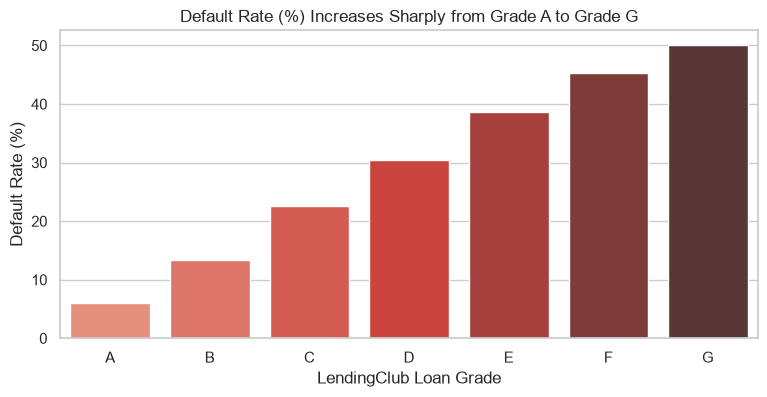

In [4]:
# ==========================================
# Q1: เกรดสินเชื่อ (Grade) ใดสร้างหนี้เสียและมูลค่าขาดทุนสูงที่สุด
# ==========================================

# จัดกลุ่มข้อมูลตามเกรดสินเชื่อ (grade) เพื่อสรุปจำนวนสัญญา ยอดปล่อยกู้ ดอกเบี้ยเฉลี่ย อัตราเบี้ยวหนี้ และยอดขาดทุนสุทธิ
grade_summary = (
    df_clean.groupby("grade", observed=True)
    .agg(
        total_loans=("loan_amnt", "count"),
        total_funded=("funded_amnt", "sum"),
        avg_int_rate=("int_rate", "mean"),
        default_rate=("is_default", "mean"),
        total_default_vol=("default_volume", "sum"),
        total_net_loss=("net_loss", "sum"),
    )
    .reset_index()
)

# แปลงอัตราส่วนเป็นร้อยละ (%) และหาสัดส่วนมูลค่าความเสียหายของแต่ละเกรดเทียบกับพอร์ตทั้งหมด
grade_summary["default_rate_%"] = grade_summary["default_rate"] * 100
grade_summary["share_of_loss_%"] = (
    grade_summary["total_net_loss"] / grade_summary["total_net_loss"].sum() * 100
)
grade_summary = grade_summary.drop(columns=["default_rate"])

# แสดงตารางสรุปความเสี่ยงและผลขาดทุนแยกตามเกรดสินเชื่อ
print("=== Credit Risk & Loss Breakdown by Loan Grade ===")
display(grade_summary.round(2))

# วาดกราฟแท่งเปรียบเทียบอัตราการเบี้ยวหนี้ (Default Rate %) ในแต่ละ Grade
plt.figure(figsize=(9, 4))
sns.barplot(data=grade_summary, x="grade", y="default_rate_%", hue="grade", palette="Reds_d", legend=False)
plt.title("Default Rate (%) Increases Sharply from Grade A to Grade G")
plt.xlabel("LendingClub Loan Grade")
plt.ylabel("Default Rate (%)")
plt.show()

=== Default Rate & Net Loss by DTI Bucket ===


,dti_bucket,total_loans,total_funded,avg_int_rate,total_net_loss,default_rate_%
0,<= 10%,238031,3220601925,12.28,"266,330,424.50",14.87
1,10-15%,264487,3829370275,12.61,"328,391,654.47",16.65
2,15-20%,280090,4128974350,13.06,"396,635,778.51",19.15
3,20-25%,233662,3443965600,13.58,"376,086,038.12",21.88
4,25-30%,162091,2377677400,14.02,"303,731,067.27",25.09
5,30-35%,90280,1281684125,15.14,"192,912,778.79",28.79
6,35-40%,27049,372328425,15.80,"60,445,912.69",31.44
7,> 40%,5620,96675150,16.91,"19,420,935.31",32.21


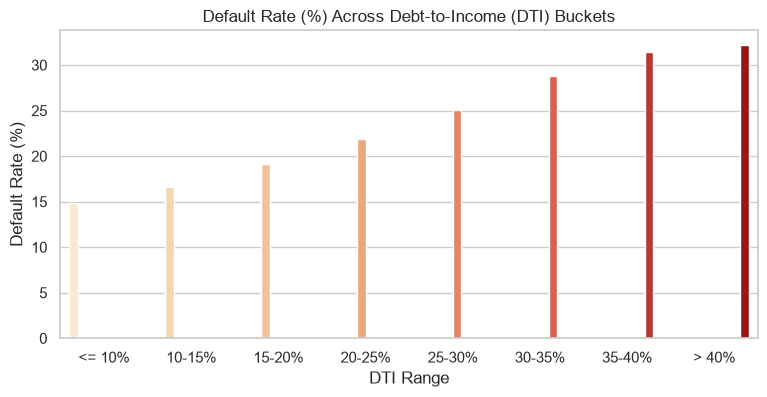

In [5]:
# ==========================================
# Q2: ภาระหนี้ต่อรายได้ (DTI) ส่งผลต่ออัตราการเบี้ยวหนี้อย่างไร
# ==========================================

# จัดกลุ่มข้อมูลตามช่วงภาระหนี้ต่อรายได้ (dti_bucket) เพื่อคำนวณสถิติความเสี่ยงและผลขาดทุน
dti_summary = (
    df_clean.groupby("dti_bucket", observed=True)
    .agg(
        total_loans=("loan_amnt", "count"),
        total_funded=("funded_amnt", "sum"),
        default_rate=("is_default", "mean"),
        avg_int_rate=("int_rate", "mean"),
        total_net_loss=("net_loss", "sum"),
    )
    .reset_index()
)

# แปลงอัตราการเบี้ยวหนี้เป็นค่าร้อยละ (%)
dti_summary["default_rate_%"] = dti_summary["default_rate"] * 100
dti_summary = dti_summary.drop(columns=["default_rate"])

# แสดงตารางสรุปความเสี่ยงและผลขาดทุนแยกตามช่วง DTI
print("=== Default Rate & Net Loss by DTI Bucket ===")
display(dti_summary.round(2))

# สร้างกราฟแท่งแสดงแนวโน้มอัตราการเบี้ยวหนี้ที่เพิ่มขึ้นตามระดับ DTI
plt.figure(figsize=(9, 4))
sns.barplot(data=dti_summary, x="dti_bucket", y="default_rate_%", hue="dti_bucket", palette="OrRd", legend=False)
plt.title("Default Rate (%) Across Debt-to-Income (DTI) Buckets")
plt.xlabel("DTI Range")
plt.ylabel("Default Rate (%)")
plt.show()

In [6]:
# ==========================================
# Q3: วัตถุประสงค์การกู้ (Purpose) ใดมีความเสี่ยงสูงสุด
# ==========================================

# จัดกลุ่มข้อมูลตามวัตถุประสงค์การกู้ (purpose) เพื่อคำนวณจำนวนสัญญา ยอดปล่อยกู้ อัตราเบี้ยวหนี้ และยอดขาดทุน
purpose_summary = (
    df_clean.groupby("purpose", observed=True)
    .agg(
        total_loans=("loan_amnt", "count"),
        total_funded=("funded_amnt", "sum"),
        default_rate=("is_default", "mean"),
        total_net_loss=("net_loss", "sum"),
    )
    .reset_index()
)

# แปลงอัตราเบี้ยวหนี้เป็นร้อยละ (%) กรองเฉพาะกลุ่มที่มีตั้งแต่ 500 สัญญาขึ้นไป และเรียงจากความเสี่ยงสูงสุดไปต่ำสุด
purpose_summary["default_rate_%"] = purpose_summary["default_rate"] * 100
purpose_summary = purpose_summary[purpose_summary["total_loans"] >= 500].sort_values(
    "default_rate_%", ascending=False
).drop(columns=["default_rate"]).reset_index(drop=True)

# แสดงตารางสรุปความเสี่ยงแยกตามวัตถุประสงค์การกู้
print("=== Risk Breakdown by Loan Purpose (Min 500 Loans) ===")
display(purpose_summary.round(2))

=== Risk Breakdown by Loan Purpose (Min 500 Loans) ===


,purpose,total_loans,total_funded,total_net_loss,default_rate_%
0,small_business,14939,232238850,"38,922,179.00",29.73
1,renewable_energy,910,9096875,"1,213,553.66",23.74
2,moving,9135,71558100,"10,178,104.49",23.44
3,medical,14979,134729225,"18,173,914.29",21.92
4,house,6950,106643375,"13,167,842.97",21.74
5,debt_consolidation,756496,11509481150,"1,232,865,769.25",21.25
6,other,74634,733079250,"92,845,519.33",21.18
7,vacation,8704,53896025,"7,119,590.16",19.23
8,major_purchase,28257,334087950,"43,798,668.71",18.71
9,home_improvement,84263,1191596425,"121,899,352.21",17.86


=== Approval Threshold Policy Simulation (Trade-off Analysis) ===


,Scenario,Approval_Rate_%,New_Default_Rate_%,Remaining_Net_Loss,Avoided_Loss_$,Lost_Good_Loan_Vol_$,Lost_Interest_Income_$,Net_Benefit_$,Portfolio_Net_Profit_$
0,Baseline (Approve All),100.00,20.07,"1,943,954,589.67",0.00,0,0.00,0.00,"500,813,008.55"
1,Policy 1: Reject Grade F & G,96.90,19.23,"1,761,085,948.13","182,868,641.54",413023925,"133,933,988.38","48,934,653.16","543,422,007.26"
2,"Policy 2: Reject Grade E, F & G",89.88,17.71,"1,455,445,629.68","488,508,959.99",1383290600,"404,520,319.90","83,988,640.09","570,533,317.41"
3,Policy 3: Reject Grade F-G OR DTI > 30%,87.98,18.34,"1,525,611,818.65","418,342,771.02",1555192025,"342,581,403.27","75,761,367.75","567,547,728.63"
4,Policy 4: Reject Grade E-G OR DTI > 25%,71.24,16.21,"1,060,342,215.09","883,612,374.57",3934270450,"828,276,386.86","55,335,987.71","537,166,425.92"
5,Policy 5: Reject Grade E-G OR DTI > 30%,82.14,17.00,"1,280,039,387.14","663,915,202.53",2388310550,"576,043,598.83","87,871,603.70","572,644,297.45"
6,Policy 6: Reject Grade D-G,74.91,15.17,"997,448,618.40","946,505,971.26",3408194600,"861,301,402.72","85,204,568.54","563,039,511.16"


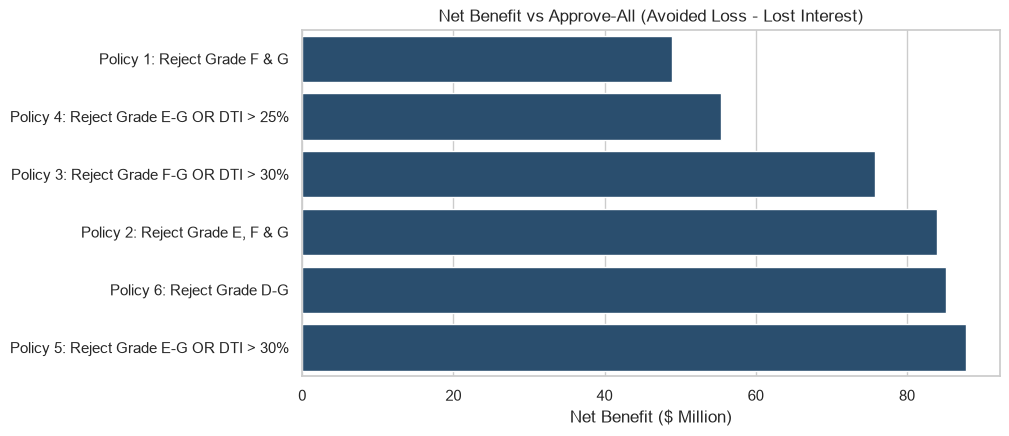

In [7]:
# ==========================================
# Q4: จำลองผลกระทบทางการเงินหากปรับเกณฑ์อนุมัติ (Approval Threshold Simulation)
# ==========================================

# กำหนดเงื่อนไขจำลองนโยบายการอนุมัติสินเชื่อ (Policy Scenarios) โดย mask = True หมายถึง "อนุมัติ"
scenarios = [
    ("Baseline (Approve All)", pd.Series(True, index=df_clean.index)),
    ("Policy 1: Reject Grade F & G", ~df_clean["grade"].isin(["F", "G"])),
    ("Policy 2: Reject Grade E, F & G", ~df_clean["grade"].isin(["E", "F", "G"])),
    ("Policy 3: Reject Grade F-G OR DTI > 30%", (~df_clean["grade"].isin(["F", "G"])) & (df_clean["dti"] <= 30)),
    ("Policy 4: Reject Grade E-G OR DTI > 25%", (~df_clean["grade"].isin(["E", "F", "G"])) & (df_clean["dti"] <= 25)),
    ("Policy 5: Reject Grade E-G OR DTI > 30%", (~df_clean["grade"].isin(["E", "F", "G"])) & (df_clean["dti"] <= 30)),
    ("Policy 6: Reject Grade D-G", ~df_clean["grade"].isin(["D", "E", "F", "G"])),
]

# คำนวณค่าตั้งต้น (Baseline) ของยอดขาดทุนรวมและยอดปล่อยกู้ของลูกค้าดีทั้งหมด
baseline_loss = df_clean["net_loss"].sum()
baseline_good_vol = df_clean.loc[df_clean["is_default"] == 0, "funded_amnt"].sum()

# วนลูปคำนวณผลลัพธ์ทางการเงินของแต่ละนโยบาย (Trade-off ระหว่างยอดหนี้เสียที่ลดได้ กับ ดอกเบี้ยรับที่เสียโอกาส)
sim_results = []
for name, mask in scenarios:
    approved = df_clean[mask]
    rejected = df_clean[~mask]
    current_loss = approved["net_loss"].sum()
    current_good_vol = approved.loc[approved["is_default"] == 0, "funded_amnt"].sum()

    # คำนวณยอดขาดทุนที่ลดลงได้ (Avoided Loss) และดอกเบี้ยสุทธิที่เสียโอกาสจากลูกค้าดีที่ถูกปฏิเสธ (Opportunity Loss)
    avoided_loss = baseline_loss - current_loss
    lost_interest = rejected.loc[rejected["is_default"] == 0, "net_profit"].sum()

    sim_results.append({
        "Scenario": name,
        "Approval_Rate_%": len(approved) / len(df_clean) * 100,
        "New_Default_Rate_%": approved["is_default"].mean() * 100,
        "Remaining_Net_Loss": current_loss,
        "Avoided_Loss_$": avoided_loss,
        "Lost_Good_Loan_Vol_$": baseline_good_vol - current_good_vol,
        "Lost_Interest_Income_$": lost_interest,
        "Net_Benefit_$": avoided_loss - lost_interest,
        "Portfolio_Net_Profit_$": approved["net_profit"].sum(),
    })

# สร้าง DataFrame สรุปผลการจำลองนโยบายการอนุมัติและแสดงผล
threshold_sim_df = pd.DataFrame(sim_results)
print("=== Approval Threshold Policy Simulation (Trade-off Analysis) ===")
display(threshold_sim_df.round(2))

# วาดกราฟแท่งแนวนอนเปรียบเทียบผลตอบแทนสุทธิ (Net Benefit) ของแต่ละนโยบายเทียบกับ Baseline
plot_df = threshold_sim_df.iloc[1:].sort_values("Net_Benefit_$")
plt.figure(figsize=(9, 4.5))
sns.barplot(data=plot_df, y="Scenario", x=plot_df["Net_Benefit_$"] / 1e6, color="#1f4e79")
plt.title("Net Benefit vs Approve-All (Avoided Loss - Lost Interest)")
plt.xlabel("Net Benefit ($ Million)")
plt.ylabel("")
plt.show()

=== Risk by term_months ===


,term_months,total_loans,total_net_loss,net_profit,default_rate_%
0,36.00,986942,"916,806,058.43","501,798,090.49",16.09
1,60.00,314368,"1,027,148,531.23","-985,081.94",32.56


=== Risk by income_bucket ===


,income_bucket,total_loans,total_net_loss,net_profit,default_rate_%
0,<= $40K,236784,"241,053,561.72","10,653,643.35",23.80
1,$40K-$60K,360727,"496,842,864.83","73,212,606.81",21.70
2,$60K-$80K,282016,"457,718,796.10","104,451,520.11",19.81
3,$80K-$100K,180613,"316,214,712.09","98,641,369.59",18.04
4,> $100K,241170,"432,124,654.92","213,853,868.69",15.80


=== Risk by revol_bucket ===


,revol_bucket,total_loans,total_net_loss,net_profit,default_rate_%
0,<= 20%,148021,"186,381,482.00","-14,587,271.76",14.93
1,20-40%,284559,"374,916,807.07","43,759,830.61",18.04
2,40-60%,360608,"536,934,078.24","138,060,772.04",20.62
3,60-80%,317224,"517,870,705.49","192,196,748.45",21.98
4,80-100%,186364,"318,880,093.29","141,019,926.24",22.77
5,> 100%,4534,"8,971,423.57","363,002.97",26.84


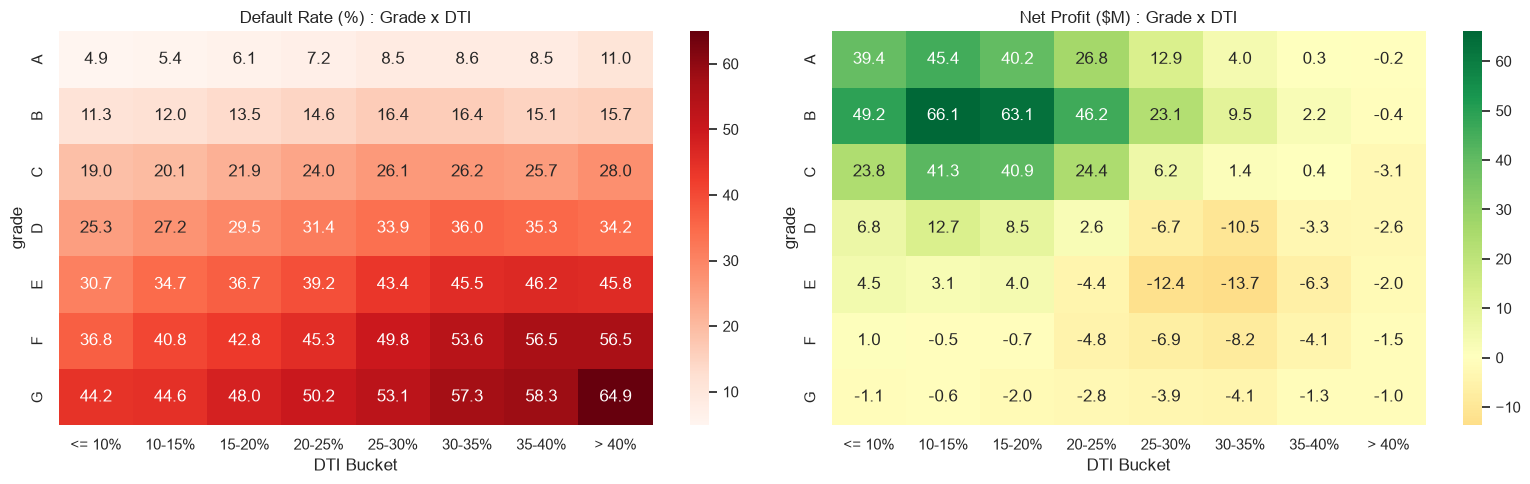

In [8]:
# ==========================================
# Q5: วิเคราะห์ปัจจัยเสี่ยงเพิ่มเติม (Term / Income / Revolving Utilization และ Grade x DTI)
# ==========================================

# สร้างฟังก์ชันสรุปตารางความเสี่ยงและกำไร/ขาดทุนสุทธิสำหรับตัวแปรที่กำหนด
def risk_table(col):
    t = (
        df_clean.groupby(col, observed=True)
        .agg(
            total_loans=("loan_amnt", "count"),
            default_rate=("is_default", "mean"),
            total_net_loss=("net_loss", "sum"),
            net_profit=("net_profit", "sum"),
        )
        .reset_index()
    )
    t["default_rate_%"] = t["default_rate"] * 100
    return t.drop(columns="default_rate")

# แสดงตารางวิเคราะห์ความเสี่ยงแยกตามระยะเวลาผ่อน (Term), ช่วงรายได้ (Income) และสัดส่วนใช้วงเงิน (Revolving Utilization)
for col in ["term_months", "income_bucket", "revol_bucket"]:
    print(f"=== Risk by {col} ===")
    display(risk_table(col).round(2))

# สร้างตาราง Pivot สำหรับวาด Heatmap เปรียบเทียบ Default Rate (%) และ Net Profit ($M) ระหว่าง Grade กับ DTI Bucket
hm_default = (
    df_clean.pivot_table(
        index="grade", columns="dti_bucket", values="is_default", aggfunc="mean", observed=True
    ) * 100
)
hm_profit = (
    df_clean.pivot_table(
        index="grade", columns="dti_bucket", values="net_profit", aggfunc="sum", observed=True
    ) / 1e6
)

# วาดกราฟ Heatmap คู่กันเพื่อระบุกลุ่มลูกค้าที่ทำกำไรและกลุ่มที่ขาดทุนสุทธิ
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(hm_default, annot=True, fmt=".1f", cmap="Reds", ax=ax[0])
ax[0].set_title("Default Rate (%) : Grade x DTI")
ax[0].set_xlabel("DTI Bucket")

sns.heatmap(hm_profit, annot=True, fmt=".1f", cmap="RdYlGn", center=0, ax=ax[1])
ax[1].set_title("Net Profit ($M) : Grade x DTI")
ax[1].set_xlabel("DTI Bucket")

plt.tight_layout()
plt.show()

In [9]:
# ==========================================
# 6. ส่งออกไฟล์ที่คลีนแล้วสำหรับนำไปสร้าง Power BI Dashboard (Star Schema)
# ==========================================

# สร้างโฟลเดอร์ชื่อ 'powerbi_data' หากยังไม่มี เพื่อใช้เก็บไฟล์ผลลัพธ์สำหรับ Power BI
os.makedirs("powerbi_data", exist_ok=True)

# ฟังก์ชันสร้างตาราง Dimension พื้นฐานพร้อม Surrogate Key
def make_dim(df, cols, key):
    d = df[cols].drop_duplicates().sort_values(cols).reset_index(drop=True)
    d[key] = np.arange(1, len(d) + 1)
    return d

# ฟังก์ชันสร้างตาราง Dimension สำหรับคอลัมน์ช่วงข้อมูล (Bucket) พร้อมคอลัมน์ sort_order สำหรับเรียงลำดับใน Power BI
def make_bucket_dim(series, col_name, key_name):
    cats = list(series.cat.categories)
    return pd.DataFrame({
        key_name: np.arange(1, len(cats) + 1),
        col_name: cats,
        "sort_order": np.arange(1, len(cats) + 1),
    })

# 1. สร้างตาราง Dimension ของหมวดหมู่ข้อมูลต่างๆ
dims = {
    "dim_grade": make_dim(df_clean, ["grade", "sub_grade"], "grade_key"),
    "dim_purpose": make_dim(df_clean, ["purpose"], "purpose_key"),
    "dim_state": make_dim(df_clean, ["addr_state"], "state_key"),
    "dim_home": make_dim(df_clean, ["home_ownership"], "home_key"),
    "dim_verification": make_dim(df_clean, ["verification_status"], "verification_key"),
    "dim_term": make_dim(df_clean, ["term_months"], "term_key"),
}

# 2. สร้างตาราง Dimension สำหรับช่วงข้อมูล (Buckets)
bucket_dims = {
    "dim_dti": make_bucket_dim(df_clean["dti_bucket"], "dti_bucket", "dti_key"),
    "dim_income": make_bucket_dim(df_clean["income_bucket"], "income_bucket", "income_key"),
    "dim_revol": make_bucket_dim(df_clean["revol_bucket"], "revol_bucket", "revol_key"),
}

# 3. สร้างตาราง Fact (fact_loan) และเชื่อม Surrogate Keys จากทุกตาราง Dimension
fact = df_clean[["loan_id"]].copy()
fact["issue_date"] = df_clean["issue_d"].dt.strftime("%Y-%m-01")

for name, d in dims.items():
    cols = [c for c in d.columns if not c.endswith("_key")]
    key = [c for c in d.columns if c.endswith("_key")][0]
    fact[key] = df_clean[cols].merge(d, on=cols, how="left")[key].values

for name, d in bucket_dims.items():
    col = [c for c in d.columns if c.endswith("_bucket")][0]
    key = [c for c in d.columns if c.endswith("_key")][0]
    mapping = dict(zip(d[col], d[key]))
    fact[key] = df_clean[col].astype(str).map(mapping).values

# รวมคอลัมน์ตัวเลขและตัวชี้วัด (Measures) เข้ากับตาราง Fact
measures = [
    "loan_amnt", "funded_amnt", "int_rate", "installment", "annual_inc", "dti", "revol_util",
    "credit_history_years", "total_pymnt", "net_loss", "net_profit", "is_default"
]
fact = pd.concat([fact, df_clean[measures].reset_index(drop=True)], axis=1)

# 4. บันทึกตาราง Fact, Dimension ทั้งหมด รวมถึงตารางสรุป Log และ Simulation เป็นไฟล์ CSV
fact.to_csv("powerbi_data/fact_loan.csv", index=False)
for name, d in {**dims, **bucket_dims}.items():
    d.to_csv(f"powerbi_data/{name}.csv", index=False)
cleaning_log.to_csv("powerbi_data/cleaning_log.csv", index=False)
threshold_sim_df.to_csv("powerbi_data/policy_simulation.csv", index=False)

# แจ้งเตือนเมื่อการประมวลผลและส่งออกไฟล์เสร็จสมบูรณ์
print("Exported:", fact.shape, "->", sorted(os.listdir("powerbi_data")))

Exported: (1301310, 23) -> ['cleaning_log.csv', 'dim_dti.csv', 'dim_grade.csv', 'dim_home.csv', 'dim_income.csv', 'dim_purpose.csv', 'dim_revol.csv', 'dim_state.csv', 'dim_term.csv', 'dim_verification.csv', 'fact_loan.csv', 'policy_simulation.csv']
